# Paso 8 – Validación de los modelos de clustering (v1, v2, v3 y v4)

Este notebook sigue la estructura del cuaderno de clase `step7a_ModelosNoSupervisados_Validación` y la aplica al **mejor modelo de cada una de las cuatro versiones** del Paso 7:

| Versión | Variables | Representación | Modelo elegido |
|---|---|---|---|
| **v1** | 13 (con edad y sexo) | Gower | PAM / K-Medoids |
| **v2** | 11 situacionales (sin edad ni sexo) | Gower | PAM / K-Medoids |
| **v3** | 13 (las de la v1) | MCA + numéricas estandarizadas (euclidiana) | K-Means |
| **v4** | 10 situacionales (v2 sin `nivel_atencion_salud_mental`) | Gower | PAM / K-Medoids |

El clustering es un análisis **exploratorio**: encuentra grupos, pero no prueba que sean reales. La validación es la parte **confirmatoria**. Del cuaderno de clase se aplican dos formas de confirmar:

1. **Validación con datos de test:** se agrupa con una parte de los datos (training), se entrena un modelo predictivo de las etiquetas y se comprueba si reproduce los grupos en datos que no vio (test).
2. **Validación de la estabilidad:** se perturban los datos o el modelo y se mide si los grupos se repiten.

La tercera forma del cuaderno, **corroborar con la literatura o con expertos**, corresponde a la revisión de los perfiles con el equipo técnico del CAR, que se plantea en el objetivo de negocio y queda fuera de este notebook.

## Métricas de comparación entre particiones

| Métrica | Función | Qué mide | Rango |
|---|---|---|---|
| **Rand Index (RI)** | `rand_score` | Proporción de pares de NNA que ambas particiones tratan igual (juntos en las dos o separados en las dos) | 0–1 |
| **Adjusted Rand Index (ARI)** | `adjusted_rand_score` | Igual que el RI, pero corregido por azar | −1 a 1 (≈0 azar, 1 perfecto) |
| **Jaccard** | `jaccard_score(..., average='macro')` | Coincidencia promedio de cada grupo entre las dos particiones (como el IoU) | 0–1 |

- `average='macro'` promedia el Jaccard de cada grupo con el mismo peso, de modo que los grupos chicos cuentan igual que los grandes. Es el que se usa como principal, porque varios perfiles son chicos (10 a 13 NNA) y son justamente los de casos complejos.
- `average='micro'` cuenta los aciertos globalmente y da más peso a los grupos grandes. Se reporta como referencia.

El RI y el ARI no dependen del nombre de las etiquetas. El **Jaccard sí**: si las dos particiones vienen de agrupamientos distintos (por ejemplo, el training y un nuevo agrupamiento del test), el grupo "0" de una no tiene por qué ser el "0" de la otra. En ese caso, antes de calcular el Jaccard se **emparejan** las etiquetas con el algoritmo húngaro (`linear_sum_assignment`), que asigna a cada grupo de una partición el grupo de la otra con el que más coincide.

# 1. Librerías y datos

In [1]:
from pathlib import Path
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import rand_score, adjusted_rand_score, jaccard_score, accuracy_score
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

SEMILLA = 2025                       # la misma semilla del cuaderno de clase
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA = BASE / 'Resultados_EnfoqueB'
X = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='dataset').set_index('id_persona')
versiones = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='versiones')
N = len(X)


def tipos_de(version):
    return dict(versiones.loc[versiones['version'] == version, ['variable', 'tipo_gower']].values)


TIPOS = {'v1': tipos_de('v1'), 'v2': tipos_de('v2'), 'v3': tipos_de('v3')}
TIPOS['v4'] = {c: t for c, t in TIPOS['v2'].items() if c != 'nivel_atencion_salud_mental'}
print(f'{N} NNA')
for v, t in TIPOS.items():
    print(f'{v}: {len(t)} variables -> {list(t)}')

161 NNA
v1: 13 variables -> ['ln_permanencia', 'edad_modelo', 'sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']
v2: 11 variables -> ['ln_permanencia', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']
v3: 13 variables -> ['ln_permanencia', 'edad_modelo', 'sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']
v4: 10 variables -> ['ln_permanencia', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'flag_rezago_escolar', 'esta

**k de cada modelo.** Se toma el k elegido en cada notebook del Paso 7 (los resultados guardados en `Resultados_EnfoqueB`). Así la validación se hace sobre los mismos modelos que se eligieron, sin volver a buscar k.

In [2]:
K = {}
for v in ['v1', 'v2', 'v3', 'v4']:
    comp = pd.read_excel(RUTA / f'Clusters_{v}.xlsx', sheet_name='comparacion_modelos').set_index('modelo')
    mejor = comp['indice_combinado'].idxmax()
    K[v] = int(comp.loc[mejor, 'k_elegido'])

# Asignaciones guardadas en el Paso 7 (para comprobar que aquí se reproducen los mismos modelos)
REF = {v: pd.read_excel(RUTA / f'Clusters_{v}.xlsx', sheet_name='asignacion').set_index('id_persona')['cluster'] for v in K}
ALGORITMO = {'v1': 'PAM (Gower)', 'v2': 'PAM (Gower)', 'v3': 'K-Means (MCA + numéricas)', 'v4': 'PAM (Gower)'}
pd.DataFrame({'modelo': ALGORITMO, 'k': K, 'n variables': {v: len(t) for v, t in TIPOS.items()}})

,modelo,k,n variables
v1,PAM (Gower),5,13
v2,PAM (Gower),6,11
v3,K-Means (MCA + numéricas),3,13
v4,PAM (Gower),7,10


# 2. Modelos con `fit` y `predict`

Para validar con datos de test, cada modelo tiene que poder **asignar a NNA nuevas** a los grupos aprendidos en el training, como hace `modelo.predict(...)` con K-Prototypes en el cuaderno de clase. Todo lo que se aprende de los datos (rangos de Gower, MCA, medias y desviaciones) se ajusta **solo con el training** y se aplica tal cual al test:

- **PAM sobre Gower (v1, v2 y v4).** Los rangos de las variables numéricas se toman del training. Una NNA nueva se asigna al **medoide más cercano** (distancia de Gower), que es la regla con la que el propio PAM forma los grupos. El algoritmo PAM (BUILD + SWAP) es el mismo del Paso 7; se agrega la opción de partir de medoides al azar, que se usa en la sección de estabilidad.
- **K-Means sobre MCA + numéricas (v3).** El MCA se ajusta con el training y las NNA del test se proyectan como **individuos suplementarios**, con la fórmula de transición: $f = \big(\tfrac{z}{Q} - c\big)\, D_c^{-1/2}\, V$, donde $z$ es la fila de indicadores de la NNA, $Q$ el número de variables cualitativas, $c$ las masas de las categorías y $V$ los ejes del training. Luego se estandariza con las medias y desviaciones del training y se usa `KMeans.predict`.

In [3]:
def gower_cruzada(A, B, tipos, rangos):
    """Distancia de Gower entre las filas de A y las de B. Los rangos de las numéricas vienen del training."""
    d = np.zeros((len(A), len(B)))
    for c, t in tipos.items():
        if t in ('num', 'ord'):
            a, b = np.asarray(A[c], float), np.asarray(B[c], float)
            d += np.minimum(np.abs(a[:, None] - b[None, :]) / rangos[c], 1) if rangos[c] > 0 else 0
        else:
            a, b = np.asarray(A[c].astype(str), object), np.asarray(B[c].astype(str), object)
            d += (a[:, None] != b[None, :])
    return d / len(tipos)


def pam(D, k, max_iter=50, init=None):
    """PAM (BUILD + SWAP), igual que en el Paso 7. Con init se parte de esos medoides en lugar de BUILD."""
    n = len(D)
    if init is None:
        med = [int(np.argmin(D.sum(1)))]
        for _ in range(1, k):
            dmin = D[:, med].min(1)
            ganancia = np.array([np.maximum(dmin - D[:, j], 0).sum() if j not in med else -1 for j in range(n)])
            med.append(int(np.argmax(ganancia)))
    else:
        med = [int(i) for i in init]
    costo = D[:, med].min(1).sum()
    for _ in range(max_iter):
        mejoro = False
        for i in range(k):
            for h in range(n):
                if h in med:
                    continue
                m = med.copy()
                m[i] = h
                c = D[:, m].min(1).sum()
                if c < costo - 1e-12:
                    costo, med, mejoro = c, m, True
        if not mejoro:
            break
    return np.array(med), D[:, med].argmin(1), costo


class PAMGower:
    def __init__(self, tipos, k, init_aleatorio=False, semilla=None):
        self.tipos, self.k, self.init_aleatorio, self.semilla = tipos, k, init_aleatorio, semilla

    def fit(self, df):
        self.rangos = {c: df[c].max() - df[c].min() for c, t in self.tipos.items() if t in ('num', 'ord')}
        D = gower_cruzada(df, df, self.tipos, self.rangos)
        init = np.random.default_rng(self.semilla).choice(len(df), self.k, replace=False) if self.init_aleatorio else None
        med, self.labels_, _ = pam(D, self.k, init=init)
        self.medoides_ = df.iloc[med]
        return self

    def predict(self, df):
        return gower_cruzada(df, self.medoides_, self.tipos, self.rangos).argmin(1)


class MCAKMeans:
    def __init__(self, tipos, k, n_init=20, init='k-means++', semilla=42, umbral_inercia=0.90):
        self.tipos, self.k, self.n_init, self.init, self.semilla, self.umbral = tipos, k, n_init, init, semilla, umbral_inercia
        self.cuali = [c for c, t in tipos.items() if t in ('cat', 'bin')]
        self.nume = [c for c, t in tipos.items() if t in ('num', 'ord')]

    def _indicadoras(self, df):
        Z = pd.get_dummies(df[self.cuali].astype(str), prefix_sep='=').astype(float)
        return Z.reindex(columns=self.columnas, fill_value=0.0) if hasattr(self, 'columnas') else Z

    def _proyectar(self, df):
        Z = self._indicadoras(df).values
        return ((Z / len(self.cuali) - self.c) / np.sqrt(self.c)) @ self.V

    def _espacio(self, df):
        num = (df[self.nume] - self.media_num) / self.sd_num
        F = (self._proyectar(df) - self.media_mca) / self.sd_mca
        return np.hstack([num.values, F])

    def fit(self, df):
        Z = self._indicadoras(df)
        self.columnas = Z.columns
        P = Z.values / Z.values.sum()
        r, self.c = P.sum(1), P.sum(0)
        S = (P - np.outer(r, self.c)) / np.sqrt(np.outer(r, self.c))
        U, s, Vt = np.linalg.svd(S, full_matrices=False)
        Q = len(self.cuali)
        eig = s ** 2
        benz = np.where(eig > 1 / Q, ((Q / (Q - 1)) * (eig - 1 / Q)) ** 2, 0)
        self.n_dim = int(np.argmax(np.cumsum(benz) / benz.sum() >= self.umbral) + 1)
        self.V = Vt[:self.n_dim].T
        F_activa = ((U * s) / np.sqrt(r)[:, None])[:, :self.n_dim]
        self.error_proyeccion = np.abs(self._proyectar(df) - F_activa).max()     # debe ser ~0
        self.media_num, self.sd_num = df[self.nume].mean(), df[self.nume].std(ddof=0)
        F = self._proyectar(df)
        self.media_mca, self.sd_mca = F.mean(0), F.std(0)
        self.E_ = self._espacio(df)
        self.km = KMeans(n_clusters=self.k, n_init=self.n_init, init=self.init, random_state=self.semilla).fit(self.E_)
        self.labels_ = self.km.labels_
        return self

    def predict(self, df):
        return self.km.predict(self._espacio(df))


def crear_modelo(v, **kw):
    return MCAKMeans(TIPOS[v], K[v], **kw) if v == 'v3' else PAMGower(TIPOS[v], K[v], **kw)

**Comprobación:** antes de validar, se ajusta cada modelo con el **100 %** de las NNA y se compara con la asignación guardada en el Paso 7. Si el ARI es 1, el modelo de este notebook es exactamente el mismo que se eligió.

In [4]:
MODELO_COMPLETO = {}
filas = []
for v in K:
    m = crear_modelo(v).fit(X)
    MODELO_COMPLETO[v] = m
    filas.append({'versión': v, 'modelo': ALGORITMO[v], 'k': K[v], 'ARI con la asignación del Paso 7': adjusted_rand_score(REF[v].loc[X.index], m.labels_),
                  'tamaños': np.bincount(m.labels_).tolist()})
print(f"Error de la proyección suplementaria del MCA sobre las filas activas (v3): {MODELO_COMPLETO['v3'].error_proyeccion:.1e}")
pd.DataFrame(filas).set_index('versión').round(3)

Error de la proyección suplementaria del MCA sobre las filas activas (v3): 1.9e-15


,modelo,k,ARI con la asignación del Paso 7,tamaños
versión,,,,
v1,PAM (Gower),5,1.0,"[36, 26, 34, 28, 37]"
v2,PAM (Gower),6,1.0,"[29, 30, 13, 44, 22, 23]"
v3,K-Means (MCA + numéricas),3,1.0,"[61, 77, 23]"
v4,PAM (Gower),7,1.0,"[26, 10, 18, 41, 21, 27, 18]"


**Comentario 2:** Los cuatro modelos ajustados aquí con el 100 % de los datos reproducen **exactamente** la asignación guardada en el Paso 7 (ARI = 1.00 en todos los casos, con los mismos tamaños de grupo). El error de la proyección suplementaria del MCA sobre las filas del propio training es ~10⁻¹⁵, lo que confirma que la fórmula de transición está bien implementada y que el `predict` de la v3 es coherente con su ajuste. Por lo tanto, lo que se valida en este notebook son los mismos modelos elegidos en el Paso 7.

# 3. Validación mediante datos de test

Se sigue el procedimiento del cuaderno de clase:
1. Dividir los datos en **training (75 %)** y **test (25 %)** antes del análisis.
2. Encontrar los k clusters con el **training**.
3. Asignar las NNA del **test** a esos clusters con la regla del propio modelo (`predict`).
4. Con el training, construir un **modelo predictivo** (KNN) de las etiquetas.
5. Predecir las etiquetas del test con el KNN y compararlas con las del clustering mediante **RI, ARI y Jaccard**.

Además del paso 3 del cuaderno de clase, se agrega la variante que su texto describe ("encontrar también K-clusters con test"): se vuelve a **agrupar el test por separado**, con el mismo algoritmo y el mismo k, y se compara esa partición con la que predice el KNN. Esta es la prueba más exigente, porque el agrupamiento del test no sabe nada del training.

> Con 161 NNA, el test tiene solo 41. Por eso, además de la partición con la semilla de clase (sección 3), en la sección 4 se **repite todo con 30 particiones distintas** para ver cuánto depende el resultado de la partición.

## 3.1 Partición de los datos

In [5]:
x_train, x_test = train_test_split(X, test_size=0.25, random_state=SEMILLA)
print('training:', x_train.shape, '| test:', x_test.shape)

training: (120, 60) | test: (41, 60)


## 3.2 Transformaciones para el modelo predictivo

Igual que en el cuaderno de clase, el KNN no trabaja con Gower sino con un espacio numérico: las variables numéricas y ordinales se **estandarizan** (`StandardScaler`) y las categóricas y binarias se pasan a **dummies** (`OneHotEncoder`, `drop='first'`). Ambos transformadores se ajustan con el training y se aplican al test. Cada versión usa sus propias variables.

In [6]:
def preparar_knn(tipos, train, test):
    nume = [c for c, t in tipos.items() if t in ('num', 'ord')]
    cuali = [c for c, t in tipos.items() if t in ('cat', 'bin')]
    scaler = StandardScaler().fit(train[nume])
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first').fit(train[cuali].astype(str))
    def transformar(df):
        num = pd.DataFrame(scaler.transform(df[nume]), columns=nume, index=df.index)
        dum = pd.DataFrame(ohe.transform(df[cuali].astype(str)), columns=ohe.get_feature_names_out(cuali), index=df.index)
        return pd.concat([num, dum], axis=1)
    return transformar(train), transformar(test)


for v in K:
    a, b = preparar_knn(TIPOS[v], x_train, x_test)
    print(f'{v}: training {a.shape} | test {b.shape}')

v1: training (120, 16) | test (41, 16)
v2: training (120, 14) | test (41, 14)
v3: training (120, 16) | test (41, 16)
v4: training (120, 13) | test (41, 13)


## 3.3 Funciones de validación

- `emparejar`: renombra las etiquetas de una partición para que coincidan con las de otra (algoritmo húngaro), solo para el Jaccard.
- `comparar`: calcula RI, ARI y Jaccard (macro y micro).
- `validar_test`: hace todo el procedimiento para una versión. El KNN se ajusta con `GridSearchCV` sobre `n_neighbors` y `p` (distancia de Minkowski: 1 = Manhattan, 2 = euclidiana), con `StratifiedKFold`, como en el cuaderno de clase. Como los grupos son chicos, el número de folds se limita al tamaño del grupo más chico del training.

In [7]:
def emparejar(referencia, otra):
    """Renombra las etiquetas de `otra` para que coincidan lo más posible con `referencia` (algoritmo húngaro)."""
    referencia, otra = np.asarray(referencia), np.asarray(otra)
    ref_u, otra_u = np.unique(referencia), np.unique(otra)
    tabla = np.array([[np.sum((otra == o) & (referencia == r)) for r in ref_u] for o in otra_u])
    fila, col = linear_sum_assignment(-tabla)
    mapa = {otra_u[f]: ref_u[c] for f, c in zip(fila, col)}
    libre = itertools.count(referencia.max() + 1)
    return np.array([mapa[o] if o in mapa else mapa.setdefault(o, next(libre)) for o in otra])


def comparar(a, b, alinear=False):
    a, b = np.asarray(a), np.asarray(b)
    b_al = emparejar(a, b) if alinear else b
    return {'RI': rand_score(a, b), 'ARI': adjusted_rand_score(a, b),
            'Jaccard_macro': jaccard_score(a, b_al, average='macro'), 'Jaccard_micro': jaccard_score(a, b_al, average='micro')}


GRILLA_KNN = {'n_neighbors': [3, 5, 7, 9, 11, 15], 'p': [1, 2, 3]}


def validar_test(v, train, test, semilla=SEMILLA, detalle=False):
    # 1) Clustering con el training y asignación del test con la regla del modelo
    modelo = crear_modelo(v).fit(train)
    lab_train = modelo.labels_
    lab_test_modelo = modelo.predict(test)
    # 2) Clustering independiente del test (mismo algoritmo y k)
    lab_test_indep = crear_modelo(v).fit(test).labels_
    # 3) Modelo predictivo KNN entrenado con las etiquetas del training
    xtr, xte = preparar_knn(TIPOS[v], train, test)
    n_folds = int(max(2, min(5, np.bincount(lab_train).min())))
    skf = StratifiedKFold(n_splits=n_folds, random_state=semilla, shuffle=True)
    grid = GridSearchCV(KNeighborsClassifier(), GRILLA_KNN, cv=skf, n_jobs=-1).fit(xtr, lab_train)
    knn = KNeighborsClassifier(**grid.best_params_).fit(xtr, lab_train)
    y_pred = knn.predict(xte)
    cv = cross_val_score(KNeighborsClassifier(**grid.best_params_), xtr, lab_train,
                         cv=StratifiedKFold(n_splits=int(max(2, min(10, np.bincount(lab_train).min()))), random_state=semilla, shuffle=True))
    res = {'versión': v, 'k': K[v], 'mejores_param_knn': grid.best_params_, 'folds': n_folds,
           'accuracy_train': knn.score(xtr, lab_train), 'accuracy_cv_media': cv.mean(), 'accuracy_cv_sd': cv.std(),
           'accuracy_test': accuracy_score(lab_test_modelo, y_pred)}
    res |= {f'{m} (modelo vs KNN)': val for m, val in comparar(lab_test_modelo, y_pred).items()}
    res |= {f'{m} (test reagrupado vs KNN)': val for m, val in comparar(y_pred, lab_test_indep, alinear=True).items()}
    res['ARI (test reagrupado vs modelo)'] = adjusted_rand_score(lab_test_modelo, lab_test_indep)
    if detalle:
        res['_extra'] = dict(lab_train=lab_train, lab_test_modelo=lab_test_modelo, lab_test_indep=lab_test_indep, y_pred=y_pred, cv=cv)
    return res

## 3.4 Resultados por modelo

Para cada versión se muestra: la distribución de los clusters en training y test, los mejores parámetros del KNN, el accuracy (training, validación cruzada y test), la **matriz de confusión** del test (filas = cluster asignado por el modelo, columnas = cluster predicho por el KNN) y las métricas RI, ARI y Jaccard.

In [8]:
RES = {}
for v in K:
    r = validar_test(v, x_train, x_test, detalle=True)
    RES[v] = r
    e = r['_extra']
    print('=' * 100)
    print(f"{v} – {ALGORITMO[v]} con k = {K[v]}")
    dist = pd.DataFrame({'training (%)': pd.Series(e['lab_train']).value_counts(normalize=True).sort_index() * 100,
                         'test asignado por el modelo (%)': pd.Series(e['lab_test_modelo']).value_counts(normalize=True).sort_index() * 100,
                         'test predicho por KNN (%)': pd.Series(e['y_pred']).value_counts(normalize=True).sort_index() * 100}).fillna(0).round(1)
    print(dist.T.to_string())
    print(f"\nKNN: mejores parámetros {r['mejores_param_knn']} (GridSearchCV con {r['folds']} folds)")
    print(f"Accuracy training = {r['accuracy_train']:.3f} | validación cruzada = {r['accuracy_cv_media']:.3f} (sd {r['accuracy_cv_sd']:.3f}) | test = {r['accuracy_test']:.3f}")
    print('\nMatriz de confusión del test (filas = cluster del modelo, columnas = predicción del KNN):')
    print(pd.crosstab(pd.Series(e['lab_test_modelo'], name='modelo'), pd.Series(e['y_pred'], name='KNN')).to_string())
    print(f"\nModelo vs KNN          -> RI = {r['RI (modelo vs KNN)']:.3f} | ARI = {r['ARI (modelo vs KNN)']:.3f} | Jaccard macro = {r['Jaccard_macro (modelo vs KNN)']:.3f} | micro = {r['Jaccard_micro (modelo vs KNN)']:.3f}")
    print(f"Test reagrupado vs KNN -> RI = {r['RI (test reagrupado vs KNN)']:.3f} | ARI = {r['ARI (test reagrupado vs KNN)']:.3f} | Jaccard macro = {r['Jaccard_macro (test reagrupado vs KNN)']:.3f} | micro = {r['Jaccard_micro (test reagrupado vs KNN)']:.3f}")

v1 – PAM (Gower) con k = 5
                                    0     1     2     3     4
training (%)                     30.0  17.5  19.2  16.7  16.7
test asignado por el modelo (%)  24.4  26.8   9.8  24.4  14.6
test predicho por KNN (%)        36.6  19.5  19.5   9.8  14.6

KNN: mejores parámetros {'n_neighbors': 5, 'p': 1} (GridSearchCV con 5 folds)
Accuracy training = 0.883 | validación cruzada = 0.808 (sd 0.106) | test = 0.659

Matriz de confusión del test (filas = cluster del modelo, columnas = predicción del KNN):
KNN      0  1  2  3  4
modelo                
0       10  0  0  0  0
1        2  6  1  1  1
2        0  0  4  0  0
3        3  2  1  3  1
4        0  0  2  0  4

Modelo vs KNN          -> RI = 0.773 | ARI = 0.322 | Jaccard macro = 0.480 | micro = 0.491
Test reagrupado vs KNN -> RI = 0.737 | ARI = 0.219 | Jaccard macro = 0.405 | micro = 0.414


v2 – PAM (Gower) con k = 6
                                    0     1    2     3     4     5
training (%)                     21.7  18.3  9.2  14.2  20.8  15.8
test asignado por el modelo (%)  22.0  22.0  4.9  12.2  24.4  14.6
test predicho por KNN (%)        31.7  19.5  2.4  14.6  19.5  12.2

KNN: mejores parámetros {'n_neighbors': 11, 'p': 1} (GridSearchCV con 5 folds)
Accuracy training = 0.892 | validación cruzada = 0.867 (sd 0.067) | test = 0.780

Matriz de confusión del test (filas = cluster del modelo, columnas = predicción del KNN):
KNN     0  1  2  3  4  5
modelo                  
0       8  0  0  0  0  1
1       1  7  0  1  0  0
2       0  0  1  1  0  0
3       1  0  0  4  0  0
4       1  1  0  0  8  0
5       2  0  0  0  0  4

Modelo vs KNN          -> RI = 0.851 | ARI = 0.505 | Jaccard macro = 0.619 | micro = 0.640
Test reagrupado vs KNN -> RI = 0.795 | ARI = 0.322 | Jaccard macro = 0.567 | micro = 0.464


v3 – K-Means (MCA + numéricas) con k = 3
                                    0     1     2
training (%)                     45.0  16.7  38.3
test asignado por el modelo (%)  58.5   4.9  36.6
test predicho por KNN (%)        61.0   2.4  36.6

KNN: mejores parámetros {'n_neighbors': 5, 'p': 2} (GridSearchCV con 5 folds)
Accuracy training = 0.958 | validación cruzada = 0.925 (sd 0.045) | test = 0.878

Matriz de confusión del test (filas = cluster del modelo, columnas = predicción del KNN):
KNN      0  1   2
modelo           
0       22  0   2
1        1  1   0
2        2  0  13

Modelo vs KNN          -> RI = 0.799 | ARI = 0.597 | Jaccard macro = 0.693 | micro = 0.783
Test reagrupado vs KNN -> RI = 0.873 | ARI = 0.746 | Jaccard macro = 0.566 | micro = 0.822


v4 – PAM (Gower) con k = 7
                                    0     1     2     3     4     5    6
training (%)                     18.3  10.8  24.2  11.7  15.0  12.5  7.5
test asignado por el modelo (%)  17.1  14.6  29.3   9.8  14.6  12.2  2.4
test predicho por KNN (%)        17.1  14.6  31.7   7.3   9.8  17.1  2.4

KNN: mejores parámetros {'n_neighbors': 5, 'p': 1} (GridSearchCV con 5 folds)
Accuracy training = 0.908 | validación cruzada = 0.849 (sd 0.073) | test = 0.902

Matriz de confusión del test (filas = cluster del modelo, columnas = predicción del KNN):
KNN     0  1   2  3  4  5  6
modelo                      
0       6  0   1  0  0  0  0
1       0  6   0  0  0  0  0
2       0  0  12  0  0  0  0
3       0  0   0  3  0  1  0
4       1  0   0  0  4  1  0
5       0  0   0  0  0  5  0
6       0  0   0  0  0  0  1

Modelo vs KNN          -> RI = 0.943 | ARI = 0.796 | Jaccard macro = 0.829 | micro = 0.822
Test reagrupado vs KNN -> RI = 0.922 | ARI = 0.732 | Jaccard macro = 0.730 | 

**Comentario 3 – resultados con la partición de clase (semilla 2025):**
- **v1 (PAM k = 5):** es la que peor se reproduce. El KNN acierta el 66 % del test y la concordancia es baja (ARI 0.32). La matriz de confusión muestra que el cluster 3 se confunde con casi todos los demás. Al reagrupar el test por separado, la coincidencia cae a ARI 0.22.
- **v2 (PAM k = 6):** mejora claramente: accuracy de test 0.78 y ARI 0.51. Los clusters grandes (0, 1 y 4) se reconocen bien. El cluster 2 (casos complejos de muy larga permanencia) tiene solo 2 NNA en el test y el KNN acierta 1.
- **v3 (K-Means k = 3):** accuracy de test 0.88, pero con solo 3 grupos es más fácil acertar. El grupo chico (cluster 1) casi no aparece en el test (2 NNA) y el KNN acierta 1.
- **v4 (PAM k = 7):** es la que **mejor se reproduce**, a pesar de tener más grupos: accuracy de test **0.90**, ARI **0.80** y Jaccard macro **0.83**. La matriz de confusión es casi diagonal, con solo 4 errores en 41 NNA. Incluso al reagrupar el test por separado, la partición coincide con la del KNN (ARI 0.73).

Las accuracy de training y de validación cruzada (0.81 a 0.93) están cerca de la de test en v2, v3 y v4, así que el KNN no está sobreajustado. En la v1 la brecha es mayor (0.81 en validación cruzada frente a 0.66 en test).

## 3.5 Resumen de la validación con datos de test

In [9]:
COLS_TEST = ['k', 'accuracy_train', 'accuracy_cv_media', 'accuracy_test', 'RI (modelo vs KNN)', 'ARI (modelo vs KNN)', 'Jaccard_macro (modelo vs KNN)',
             'RI (test reagrupado vs KNN)', 'ARI (test reagrupado vs KNN)', 'Jaccard_macro (test reagrupado vs KNN)', 'ARI (test reagrupado vs modelo)']
res_test = pd.DataFrame([{c: r[c] for c in COLS_TEST} | {'versión': v} for v, r in RES.items()]).set_index('versión')
res_test.T.round(3)

versión,v1,v2,v3,v4
k,5.000,6.000,3.000,7.000
accuracy_train,0.883,0.892,0.958,0.908
accuracy_cv_media,0.808,0.867,0.925,0.849
accuracy_test,0.659,0.780,0.878,0.902
RI (modelo vs KNN),0.773,0.851,0.799,0.943
ARI (modelo vs KNN),0.322,0.505,0.597,0.796
Jaccard_macro (modelo vs KNN),0.480,0.619,0.693,0.829
RI (test reagrupado vs KNN),0.737,0.795,0.873,0.922
ARI (test reagrupado vs KNN),0.219,0.322,0.746,0.732
Jaccard_macro (test reagrupado vs KNN),0.405,0.567,0.566,0.730


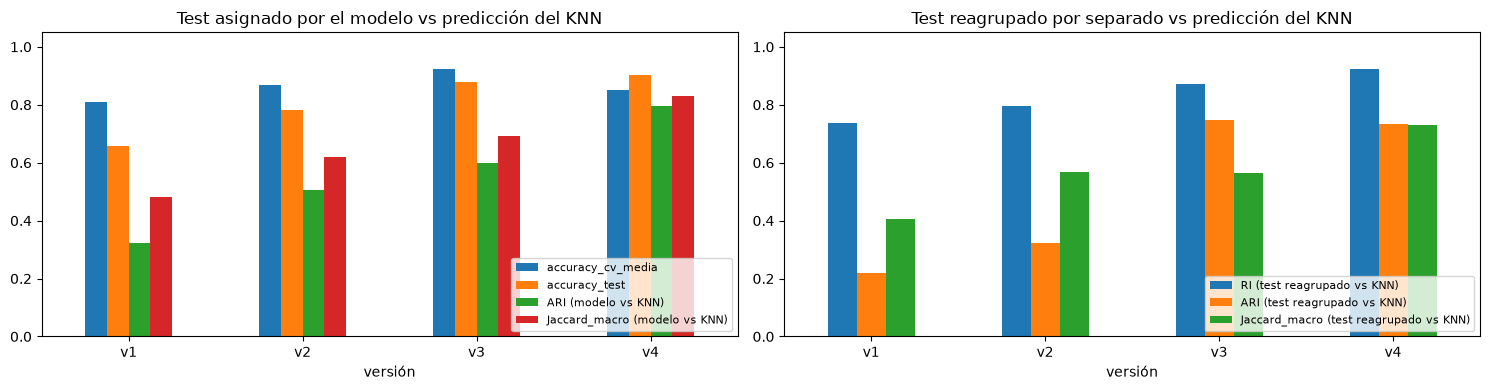

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
res_test[['accuracy_cv_media', 'accuracy_test', 'ARI (modelo vs KNN)', 'Jaccard_macro (modelo vs KNN)']].plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Test asignado por el modelo vs predicción del KNN')
ax[0].set_ylim(0, 1.05)
ax[0].legend(fontsize=8, loc='lower right')
res_test[['RI (test reagrupado vs KNN)', 'ARI (test reagrupado vs KNN)', 'Jaccard_macro (test reagrupado vs KNN)']].plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Test reagrupado por separado vs predicción del KNN')
ax[1].set_ylim(0, 1.05)
ax[1].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

**Comentario 4:** Con la partición de clase, el orden es **v4 > v3 > v2 > v1** en casi todas las métricas. Hay que leer la v3 con cuidado: con k = 3 la tarea del KNN es mucho más fácil que con k = 6 o 7 (por azar ya se acertaría alrededor de un tercio), así que su accuracy alta no indica por sí sola grupos mejor definidos. Que la v4 obtenga métricas iguales o mejores **con 7 grupos** es una señal más fuerte. La última fila (ARI entre el test reagrupado y el test asignado por el modelo) va en el mismo sentido: 0.83 en la v4, 0.69 en la v3, 0.42 en la v2 y 0.23 en la v1.

# 4. Repetición con varias particiones training/test

Una sola partición de 41 NNA de test puede ser favorable o desfavorable por azar. Se repite el procedimiento de la sección 3 con **30 semillas distintas** y se resume la media y la desviación estándar de cada métrica.

In [11]:
SEMILLAS = range(30)
rep = []
for s in SEMILLAS:
    tr, te = train_test_split(X, test_size=0.25, random_state=s)
    for v in K:
        r = validar_test(v, tr, te, semilla=s)
        rep.append({c: r[c] for c in COLS_TEST} | {'versión': v, 'semilla': s})
rep = pd.DataFrame(rep)
METRICAS_REP = ['accuracy_cv_media', 'accuracy_test', 'ARI (modelo vs KNN)', 'Jaccard_macro (modelo vs KNN)',
                'ARI (test reagrupado vs KNN)', 'Jaccard_macro (test reagrupado vs KNN)', 'ARI (test reagrupado vs modelo)']
res_rep = rep.groupby('versión')[METRICAS_REP].agg(['mean', 'std'])
res_rep.T.round(3)

versión                                         v1     v2     v3     v4
accuracy_cv_media                      mean  0.803  0.849  0.919  0.860
                                       std   0.039  0.038  0.025  0.031
accuracy_test                          mean  0.772  0.824  0.895  0.835
                                       std   0.060  0.070  0.055  0.059
ARI (modelo vs KNN)                    mean  0.501  0.637  0.714  0.675
                                       std   0.111  0.125  0.141  0.115
Jaccard_macro (modelo vs KNN)          mean  0.618  0.674  0.756  0.691
                                       std   0.087  0.131  0.103  0.106
ARI (test reagrupado vs KNN)           mean  0.264  0.418  0.452  0.473
                                       std   0.115  0.104  0.202  0.104
Jaccard_macro (test reagrupado vs KNN) mean  0.384  0.449  0.503  0.473
                                       std   0.098  0.086  0.118  0.097
ARI (test reagrupado vs modelo)        mean  0.297  0.474  0.481  0.542
                                       std   0.112  0.107  0.185  0.120

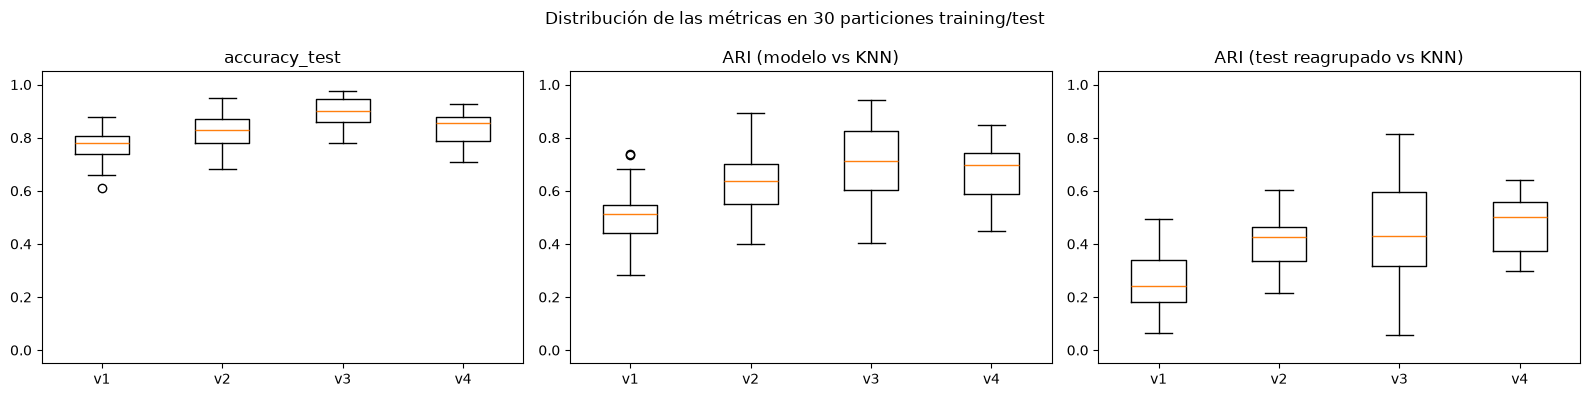

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, m in zip(ax, ['accuracy_test', 'ARI (modelo vs KNN)', 'ARI (test reagrupado vs KNN)']):
    a.boxplot([rep.loc[rep['versión'] == v, m] for v in K])
    a.set_xticks(range(1, len(K) + 1), list(K))
    a.set_title(m)
    a.set_ylim(-0.05, 1.05)
plt.suptitle('Distribución de las métricas en 30 particiones training/test')
plt.tight_layout()
plt.show()

**Comentario 5:** Con 30 particiones distintas, las conclusiones se mantienen, pero los valores de la semilla 2025 resultan algo optimistas para la v4 y pesimistas para la v1:

| Métrica (media de 30 particiones) | v1 | v2 | v3 | v4 |
|---|---|---|---|---|
| Accuracy de test | 0.77 | 0.82 | **0.90** | 0.84 |
| ARI modelo vs KNN | 0.50 | 0.64 | **0.71** | 0.68 |
| ARI test reagrupado vs KNN | 0.26 | 0.42 | 0.45 | **0.47** |
| ARI test reagrupado vs modelo | 0.30 | 0.47 | 0.48 | **0.54** |

- En la reproducción por KNN, la v3 queda primera, pero como se dijo, con 3 grupos la tarea es más fácil. Entre los modelos de 5 a 7 grupos, la **v4** supera a la v2 y ambas superan claramente a la **v1**.
- En la prueba más exigente (reagrupar el test de forma independiente), la **v4** es la mejor y la que menos varía (sd 0.10, frente a 0.20 de la v3).
- Los ARI del test reagrupado son moderados (0.26 a 0.54) en todas las versiones. Es esperable: agrupar solo 41 NNA en 5 a 7 grupos deja grupos de 3 a 8 NNA, y PAM sobre tan pocos casos es muy sensible. No significa que los perfiles no existan, sino que con esta población chica la partición tiene que leerse como **orientativa**, como ya se advertía en el Paso 7.

# 5. Modelo final con el 100 % de los datos

Como en el cuaderno de clase, una vez validado el procedimiento, el **modelo final** se entrena con todas las NNA (es el modelo del Paso 7, comprobado en la sección 2). Aquí se compara con el modelo de training de la sección 3:
- la **distribución** de los grupos en el training y en el modelo final;
- el **ARI** entre las etiquetas del training y las del modelo final para esas mismas 120 NNA (si es alto, agregar el 25 % restante no cambia los grupos).

In [13]:
filas = []
for v in K:
    lab_final = pd.Series(MODELO_COMPLETO[v].labels_, index=X.index)
    lab_tr = RES[v]['_extra']['lab_train']
    p_tr = np.sort(np.bincount(lab_tr) / len(lab_tr) * 100)[::-1].round(1).tolist()
    p_fi = np.sort(np.bincount(lab_final) / N * 100)[::-1].round(1).tolist()
    filas.append({'versión': v, 'ARI training vs modelo final (mismas NNA)': adjusted_rand_score(lab_final.loc[x_train.index], lab_tr),
                  '% por grupo, training (de mayor a menor)': p_tr, '% por grupo, modelo final (de mayor a menor)': p_fi})
res_final = pd.DataFrame(filas).set_index('versión')
res_final.round(3)

,ARI training vs modelo final (mismas NNA),"% por grupo, training (de mayor a menor)","% por grupo, modelo final (de mayor a menor)"
versión,,,
v1,0.322,"[30.0, 19.2, 17.5, 16.7, 16.7]","[23.0, 22.4, 21.1, 17.4, 16.1]"
v2,0.736,"[21.7, 20.8, 18.3, 15.8, 14.2, 9.2]","[27.3, 18.6, 18.0, 14.3, 13.7, 8.1]"
v3,0.928,"[45.0, 38.3, 16.7]","[47.8, 37.9, 14.3]"
v4,0.908,"[24.2, 18.3, 15.0, 12.5, 11.7, 10.8, 7.5]","[25.5, 16.8, 16.1, 13.0, 11.2, 11.2, 6.2]"


**Comentario 6:** Al pasar del training (120 NNA) al modelo final (161 NNA), la **v3 (ARI 0.93)** y la **v4 (ARI 0.91)** mantienen casi los mismos grupos, y la v2 los mantiene en buena medida (0.74). La **v1 cambia bastante (0.32)**: con el 75 % de los datos, PAM encuentra otra solución de 5 grupos, con proporciones distintas (el grupo mayor reúne al 30 % de las NNA, frente al 23 % en el modelo final). Es decir, la partición de la v1 depende de qué NNA estén en los datos. Las distribuciones por grupo de v2, v3 y v4 son parecidas entre el training y el modelo final.

# 6. Validación de la estabilidad

*Principio de estabilidad: "si un hallazgo se repite consistentemente bajo pequeñas variaciones de los datos o del modelo, es más probable que sea real".*

Se usa el 100 % de los datos y se generan perturbaciones. De las que lista el cuaderno de clase se aplican dos:

1. **Subsampling + inicialización aleatoria** (el ejemplo del cuaderno): en cada repetición se toma el 80 % de las NNA al azar y se ajusta el modelo partiendo de **centros al azar** (medoides al azar en PAM; `init='random'`, `n_init=1` en K-Means). Luego se asigna a **todas** las NNA con `predict`, y se calcula el ARI entre todos los pares de repeticiones. Para la v3, el MCA también se vuelve a ajustar en cada submuestra, de modo que se perturba todo el procedimiento.
2. **Random corruptions:** en cada repetición se "corrompe" el 5 % de los valores de cada variable, reemplazándolos por el valor de otra NNA elegida al azar. Se vuelve a ajustar el modelo con todos los datos corrompidos y se compara con la partición original (ARI).

Igual que en el Paso 7, un ARI medio ≥ 0.75 se lee como partición estable.

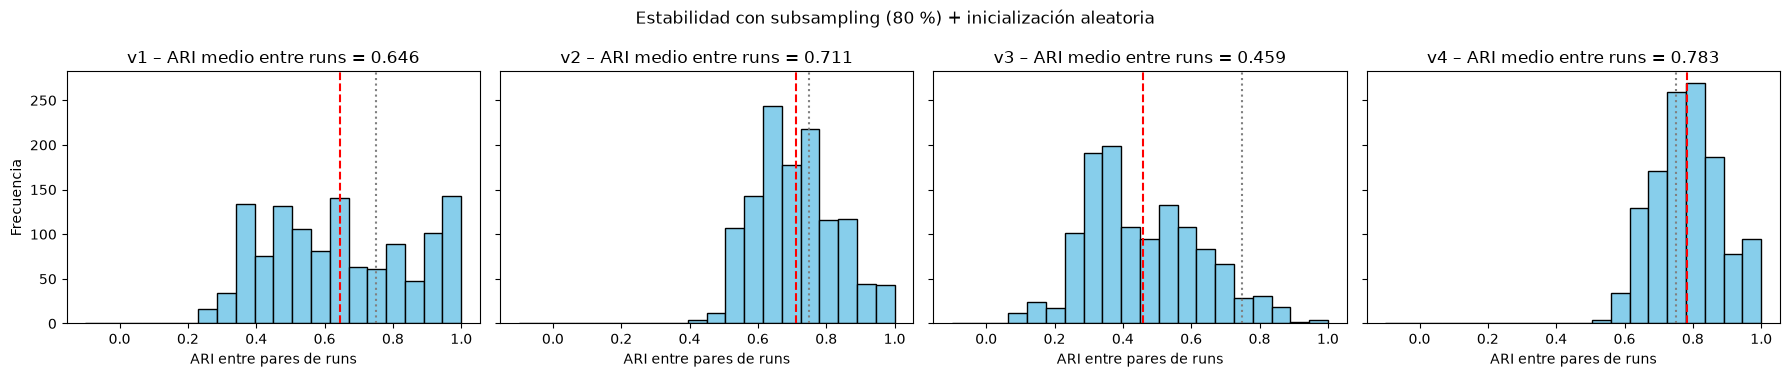

,v1,v2,v3,v4
ARI medio entre runs,0.646,0.711,0.459,0.783
ARI sd entre runs,0.212,0.117,0.170,0.098
% de pares con ARI ≥ 0.75,34.939,35.429,5.469,63.592
ARI medio vs modelo final,0.774,0.778,0.532,0.841


In [14]:
N_RUNS = 50
FRAC = 0.8


def estabilidad_subsampling(v, n_runs=N_RUNS, frac=FRAC, semilla=0):
    rng = np.random.default_rng(semilla)
    etiquetas = np.zeros((n_runs, N), dtype=int)
    for i in range(n_runs):
        idx = rng.choice(N, int(frac * N), replace=False)
        s = int(rng.integers(1_000_000))
        if v == 'v3':
            m = MCAKMeans(TIPOS[v], K[v], n_init=1, init='random', semilla=s)
        else:
            m = PAMGower(TIPOS[v], K[v], init_aleatorio=True, semilla=s)
        etiquetas[i] = m.fit(X.iloc[idx]).predict(X)
    pares = [adjusted_rand_score(etiquetas[i], etiquetas[j]) for i in range(n_runs) for j in range(i + 1, n_runs)]
    vs_ref = [adjusted_rand_score(MODELO_COMPLETO[v].labels_, etiquetas[i]) for i in range(n_runs)]
    return np.array(pares), np.array(vs_ref)


ESTAB = {v: estabilidad_subsampling(v) for v in K}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, v in zip(ax, K):
    pares = ESTAB[v][0]
    a.hist(pares, bins=20, range=(-0.1, 1), color='skyblue', edgecolor='black')
    a.axvline(pares.mean(), color='red', ls='--')
    a.axvline(0.75, color='gray', ls=':')
    a.set_title(f'{v} – ARI medio entre runs = {pares.mean():.3f}')
    a.set_xlabel('ARI entre pares de runs')
ax[0].set_ylabel('Frecuencia')
plt.suptitle('Estabilidad con subsampling (80 %) + inicialización aleatoria')
plt.tight_layout()
plt.show()
pd.DataFrame({v: {'ARI medio entre runs': p.mean(), 'ARI sd entre runs': p.std(), '% de pares con ARI ≥ 0.75': (p >= 0.75).mean() * 100,
                  'ARI medio vs modelo final': r.mean()} for v, (p, r) in ESTAB.items()}).round(3)

**Comentario 7:** Con subsampling del 80 % e **inicialización aleatoria** (centros al azar, una sola inicialización, como en el ejemplo del cuaderno):
- **v4** es la más estable: ARI medio entre runs **0.78** (la única por encima de 0.75), la menor dispersión (sd 0.10) y 64 % de pares con ARI ≥ 0.75. Comparada con el modelo final, el ARI medio es 0.84.
- **v2** (0.71) y **v1** (0.65) quedan por debajo del umbral. La v1 tiene una dispersión alta (sd 0.21): según la submuestra y los medoides iniciales, llega a soluciones bastante distintas.
- **v3** es la menos estable (0.46). K-Means con una sola inicialización aleatoria cae en óptimos locales distintos. En el Paso 7 se usó `n_init=20`, que reduce este problema, pero esta prueba muestra que la estructura de la v3 no tiene un óptimo claro.

Estos ARI son más bajos que los del Paso 7 (donde se usaba la inicialización BUILD, determinista) porque aquí también se perturba la inicialización, que es una prueba más exigente.

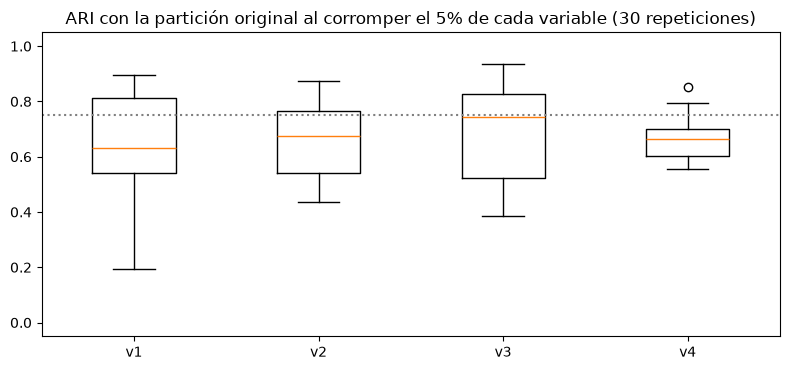

,v1,v2,v3,v4
ARI medio,0.637,0.649,0.686,0.666
ARI sd,0.205,0.134,0.166,0.070
ARI mínimo,0.195,0.436,0.385,0.554
% con ARI ≥ 0.75,40.000,30.000,50.000,13.333


In [15]:
N_CORR, TASA = 30, 0.05


def estabilidad_corrupcion(v, n_runs=N_CORR, tasa=TASA, semilla=0):
    rng = np.random.default_rng(semilla)
    ref = MODELO_COMPLETO[v].labels_
    aris = []
    for _ in range(n_runs):
        Xc = X.copy()
        for c in TIPOS[v]:
            filas_c = rng.choice(N, max(1, int(round(tasa * N))), replace=False)
            Xc.iloc[filas_c, Xc.columns.get_loc(c)] = X[c].iloc[rng.choice(N, len(filas_c))].values
        aris.append(adjusted_rand_score(ref, crear_modelo(v).fit(Xc).labels_))
    return np.array(aris)


CORR = {v: estabilidad_corrupcion(v) for v in K}
plt.figure(figsize=(8, 3.8))
plt.boxplot([CORR[v] for v in K])
plt.xticks(range(1, len(K) + 1), list(K))
plt.axhline(0.75, color='gray', ls=':')
plt.title(f'ARI con la partición original al corromper el {TASA:.0%} de cada variable ({N_CORR} repeticiones)')
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()
pd.DataFrame({v: {'ARI medio': a.mean(), 'ARI sd': a.std(), 'ARI mínimo': a.min(), '% con ARI ≥ 0.75': (a >= 0.75).mean() * 100} for v, a in CORR.items()}).round(3)

**Comentario 8:** La corrupción del 5 % de cada variable es una perturbación fuerte: con 10 a 13 variables, entre el 40 % y el 50 % de las NNA tiene al menos un valor reemplazado. Ninguna versión llega a 0.75 en promedio (ARI de 0.64 a 0.69) y las cuatro quedan muy cerca entre sí. La **v4** tiene la **menor dispersión (sd 0.07) y el mínimo más alto (0.55)**, es decir, nunca se desarma. La v1 llega a caer a 0.20 en alguna repetición. La lectura práctica es que los perfiles son **sensibles a los errores de registro**, lo que refuerza la importancia de los tratamientos de calidad de los Pasos 3 y 4 y de mantener la ficha nominal actualizada.

## 6.1 Estabilidad por grupo

El ARI resume toda la partición, pero un modelo puede ser estable en general y tener un grupo que se deshace. Para cada grupo del modelo final se calcula, en las repeticiones de subsampling, el **Jaccard máximo** con algún grupo de la repetición (el criterio de Hennig, 2007, usado en `clusterboot` de R): un grupo con Jaccard medio ≥ 0.75 se considera estable; entre 0.6 y 0.75, con patrón válido pero sin ubicación precisa; y por debajo de 0.5, "disuelto".

In [16]:
def jaccard_por_grupo(v, n_runs=N_RUNS, frac=FRAC, semilla=1):
    rng = np.random.default_rng(semilla)
    ref = MODELO_COMPLETO[v].labels_
    J = np.zeros((n_runs, K[v]))
    for i in range(n_runs):
        idx = np.sort(rng.choice(N, int(frac * N), replace=False))
        s = int(rng.integers(1_000_000))
        m = MCAKMeans(TIPOS[v], K[v], n_init=1, init='random', semilla=s) if v == 'v3' else PAMGower(TIPOS[v], K[v], init_aleatorio=True, semilla=s)
        lab = m.fit(X.iloc[idx]).labels_
        r_sub = ref[idx]
        for g in range(K[v]):
            A = set(np.where(r_sub == g)[0])
            J[i, g] = max(len(A & set(np.where(lab == h)[0])) / len(A | set(np.where(lab == h)[0])) for h in np.unique(lab)) if A else np.nan
    return pd.DataFrame({'n': np.bincount(ref), 'Jaccard medio': np.nanmean(J, 0), '% runs con Jaccard ≥ 0.75': (J >= 0.75).mean(0) * 100})


JG = {}
for v in K:
    JG[v] = jaccard_por_grupo(v)
    print(f'\n{v} – {ALGORITMO[v]} k = {K[v]}')
    print(JG[v].round(3).to_string())


v1 – PAM (Gower) k = 5
    n  Jaccard medio  % runs con Jaccard ≥ 0.75
0  36          0.832                       68.0
1  26          0.852                       76.0
2  34          0.820                       72.0
3  28          0.914                       88.0
4  37          0.882                       88.0



v2 – PAM (Gower) k = 6
    n  Jaccard medio  % runs con Jaccard ≥ 0.75
0  29          0.689                       42.0
1  30          0.907                       96.0
2  13          0.545                       36.0
3  44          0.849                       84.0
4  22          0.935                      100.0
5  23          0.750                       40.0



v3 – K-Means (MCA + numéricas) k = 3
    n  Jaccard medio  % runs con Jaccard ≥ 0.75
0  61          0.633                       26.0
1  77          0.714                       56.0
2  23          0.338                        8.0



v4 – PAM (Gower) k = 7
    n  Jaccard medio  % runs con Jaccard ≥ 0.75
0  26          0.949                      100.0
1  10          0.480                       34.0
2  18          0.770                       64.0
3  41          0.839                       72.0
4  21          0.885                       96.0
5  27          0.768                       56.0
6  18          0.813                       70.0


**Comentario 9 – estabilidad por grupo (Jaccard de Hennig):**
- **v1:** los 5 grupos son estables (Jaccard de 0.82 a 0.91). Su inestabilidad global viene de que, entre submuestras, la frontera entre grupos se mueve, no de que algún grupo se deshaga. Aun así, recuérdese que son grupos definidos en buena parte por el sexo.
- **v2:** 4 de 6 grupos son estables. El **cluster 2** (casos complejos de muy larga permanencia, 13 NNA) tiene Jaccard 0.55, cerca de "disuelto", y el cluster 0 (0.69) es un patrón válido pero sin ubicación precisa.
- **v3:** ninguno de los 3 grupos llega a 0.75, y el cluster 2 (23 NNA) se disuelve (0.34).
- **v4:** 6 de 7 grupos son estables, varios por encima de 0.85 (cluster 0 = 0.95; cluster 4 = 0.89). La excepción es el **cluster 1** (adolescentes con salud crónica, rezago escolar y malnutrición, 10 NNA), con Jaccard **0.48** ("disuelto"). Coincide con lo visto en el Paso 7, donde era el único perfil con silueta negativa.

En las versiones v2 y v4, el grupo inestable es el mismo tipo de caso: **pocos residentes con salud crónica y larga permanencia**, que no forman un grupo compacto sino un conjunto de casos complejos distintos entre sí. Debe presentarse al equipo técnico como un grupo para **revisión caso por caso**, no como un perfil homogéneo.

# 7. Comparación final de la validación

In [17]:
resumen = pd.DataFrame({
    'modelo': ALGORITMO, 'k': K,
    'accuracy test (semilla 2025)': res_test['accuracy_test'],
    'ARI test modelo vs KNN (30 particiones)': res_rep[('ARI (modelo vs KNN)', 'mean')],
    'Jaccard macro modelo vs KNN (30 particiones)': res_rep[('Jaccard_macro (modelo vs KNN)', 'mean')],
    'ARI test reagrupado vs KNN (30 particiones)': res_rep[('ARI (test reagrupado vs KNN)', 'mean')],
    'ARI training vs modelo final': res_final['ARI training vs modelo final (mismas NNA)'],
    'ARI subsampling + init aleatoria': {v: p.mean() for v, (p, r) in ESTAB.items()},
    'ARI con corrupción 5 %': {v: a.mean() for v, a in CORR.items()},
    'grupos estables (Jaccard ≥ 0.75)': {v: f"{int((JG[v]['Jaccard medio'] >= 0.75).sum())} de {K[v]}" for v in K},
})
resumen.T

,v1,v2,v3,v4
modelo,PAM (Gower),PAM (Gower),K-Means (MCA + numéricas),PAM (Gower)
k,5,6,3,7
accuracy test (semilla 2025),0.658537,0.780488,0.878049,0.902439
ARI test modelo vs KNN (30 particiones),0.501245,0.63713,0.714213,0.674926
Jaccard macro modelo vs KNN (30 particiones),0.617887,0.673874,0.756278,0.690619
ARI test reagrupado vs KNN (30 particiones),0.264335,0.418222,0.452139,0.473285
ARI training vs modelo final,0.32246,0.735644,0.927719,0.908382
ARI subsampling + init aleatoria,0.645604,0.711143,0.458566,0.783445
ARI con corrupción 5 %,0.636696,0.649416,0.686449,0.665575
grupos estables (Jaccard ≥ 0.75),5 de 5,4 de 6,0 de 3,6 de 7


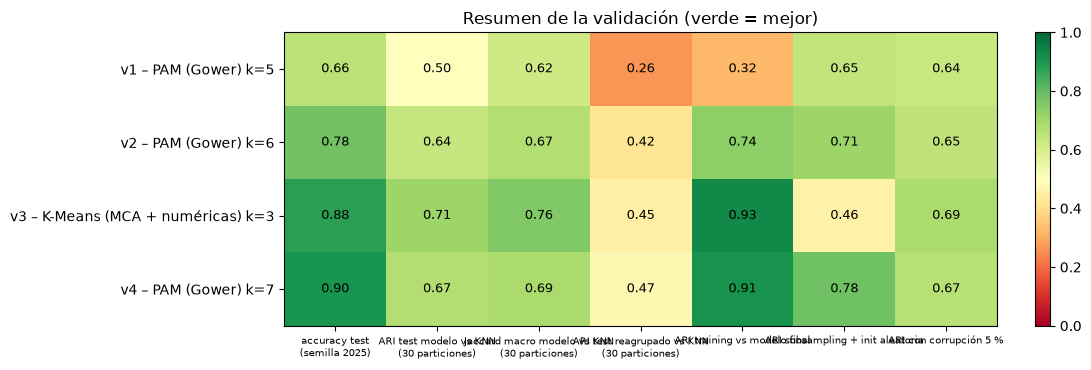

In [18]:
num = resumen.drop(columns=['modelo', 'k', 'grupos estables (Jaccard ≥ 0.75)']).astype(float)
plt.figure(figsize=(11, 3.8))
plt.imshow(num.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
plt.xticks(range(num.shape[1]), [c.replace(' (', '\n(') for c in num.columns], fontsize=7, rotation=0)
plt.yticks(range(num.shape[0]), [f'{v} – {ALGORITMO[v]} k={K[v]}' for v in num.index])
for i in range(num.shape[0]):
    for j in range(num.shape[1]):
        plt.text(j, i, f'{num.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(fraction=0.02)
plt.title('Resumen de la validación (verde = mejor)')
plt.tight_layout()
plt.show()

**Comentario 10 – conclusión de la validación.**

| Criterio | v1 PAM k=5 | v2 PAM k=6 | v3 K-Means k=3 | **v4 PAM k=7** |
|---|---|---|---|---|
| Reproducción en test por KNN (ARI, 30 particiones) | 0.50 | 0.64 | **0.71** ⚠ | 0.68 |
| Test reagrupado de forma independiente (ARI) | 0.26 | 0.42 | 0.45 | **0.47** |
| Training vs modelo final (ARI) | 0.32 | 0.74 | **0.93** | 0.91 |
| Subsampling + inicialización aleatoria (ARI) | 0.65 | 0.71 | 0.46 | **0.78** |
| Corrupción del 5 % (ARI medio / mínimo) | 0.64 / 0.20 | 0.65 / 0.44 | **0.69** / 0.39 | 0.67 / **0.55** |
| Grupos estables (Jaccard ≥ 0.75) | **5 de 5** | 4 de 6 | 0 de 3 | 6 de 7 |

⚠ La v3 tiene solo 3 grupos, lo que facilita la clasificación, y sus grupos no reconocen las situaciones del objetivo de negocio (Paso 7, versión 3).

1. **La v4 es el modelo mejor validado.** Es la más estable ante el subsampling (la única con ARI ≥ 0.75), la mejor en la prueba de test más exigente, casi no cambia entre el training y el modelo final, y 6 de sus 7 grupos son estables. Además tiene la mejor separación del Paso 7 (silueta 0.36).
2. **La v2 queda segunda** y valida razonablemente. La v4 es, en lo esencial, la v2 con un perfil más (ARI entre ambas = 0.75), así que **las dos versiones se confirman mutuamente**: los perfiles de PTI vigente con y sin alerta nutricional, medida firme con larga permanencia y niñez sin PTI vigente aparecen en ambas y son estables.
3. **La v1** tiene grupos internamente estables, pero su partición depende de qué NNA estén en los datos (ARI 0.32 entre training y modelo final) y es la que peor se reproduce en el test.
4. **La v3** se reproduce bien por tener pocos grupos, pero es la menos estable ante la inicialización y ninguno de sus grupos supera el umbral de Hennig.

**Implicancia para la elección final.** En la comparación del Paso 7 (notebook de la v3) la mejor era la v2, y la v4 todavía no existía. La validación favorece a la **v4**. Elegirla implica aceptar que el **nivel de atención en salud mental deja de formar los grupos** y pasa a ser una variable **descriptiva** de cada perfil (sección 12 del notebook de la v4). Si para el equipo es indispensable que el área psicoemocional participe en la segmentación, la v2 sigue siendo una alternativa válida, con una estabilidad algo menor. En ambos casos, el grupo chico de casos complejos (cluster 2 en la v2 y cluster 1 en la v4) no es estable y debe revisarse caso por caso.

**Limitaciones.** Con 161 NNA, el test tiene 41, y algunos grupos aparecen con 1 o 2 casos, por lo que las métricas por partición varían bastante (de ahí la repetición con 30 particiones). La validación con datos de test confirma que los grupos se pueden **reconocer** a partir de las variables, pero no que sean "reales": eso requiere la corroboración con el equipo técnico, que es la tercera forma de validación del cuaderno de clase.

# 8. Guardado

In [19]:
with pd.ExcelWriter(RUTA / 'Validacion_modelos.xlsx') as w:
    resumen.reset_index(names='versión').to_excel(w, sheet_name='resumen', index=False)
    res_test.assign(mejores_param_knn=[str(RES[v]['mejores_param_knn']) for v in res_test.index]).reset_index().to_excel(w, sheet_name='test_semilla_2025', index=False)
    rep.to_excel(w, sheet_name='test_30_particiones', index=False)
    res_final.astype(str).reset_index().to_excel(w, sheet_name='modelo_final', index=False)
    pd.DataFrame({v: {'ARI medio': p.mean(), 'ARI sd': p.std()} for v, (p, r) in ESTAB.items()}).T.reset_index(names='versión').to_excel(w, sheet_name='estab_subsampling', index=False)
    pd.DataFrame({v: {'ARI medio': a.mean(), 'ARI sd': a.std()} for v, a in CORR.items()}).T.reset_index(names='versión').to_excel(w, sheet_name='estab_corrupcion', index=False)
    pd.concat({v: JG[v] for v in K}).reset_index(names=['versión', 'cluster']).to_excel(w, sheet_name='estab_por_grupo', index=False)
print('Guardado:', (RUTA / 'Validacion_modelos.xlsx').relative_to(BASE))

Guardado: Resultados_EnfoqueB\Validacion_modelos.xlsx


**Comentario 11:** Los resultados se guardan en `Resultados_EnfoqueB/Validacion_modelos.xlsx`: resumen comparativo, validación con la semilla 2025, las 30 particiones, el contraste con el modelo final y las tres pruebas de estabilidad (subsampling, corrupción y por grupo).

# 9. Perfiles finales

In [20]:
v4 = pd.read_excel(RUTA / 'Clusters_v4.xlsx', sheet_name='asignacion').set_index('id_persona').loc[X.index]
NOMBRES = {   # nombres asignados en la sección 12 del notebook de la v4
    0: 'P0 Provisional prolongada con PTI vigente, sin alerta nutricional',
    1: 'P1 Adolescentes con salud crónica, rezago escolar y malnutrición',
    2: 'P2 Sin PTI elaborado y con malnutrición',
    3: 'P3 PTI vigente con alerta nutricional',
    4: 'P4 Adolescentes con medida firme y larga permanencia',
    5: 'P5 Niñez sin PTI vigente y sin alerta nutricional',
    6: 'P6 Provisional prolongada con PTI vencido y malnutrición',
}
PF = X.assign(perfil=v4['cluster'], perfil_nombre=v4['cluster'].map(NOMBRES))
for v in ['v1', 'v2', 'v3']:
    PF[f'cluster_{v}'] = REF[v].loc[X.index]
resumen_perfiles = PF.groupby('perfil_nombre').agg(
    NNA=('perfil', 'size'), edad_mediana=('edad_anios', 'median'),
    permanencia_mediana_anios=('meses_permanencia', lambda s: round(s.median() / 12, 1)),
    pct_provisional_18m=('provisional_prolongada', lambda s: round(s.mean() * 100)),
    pct_pti_no_vigente=('estado_pti', lambda s: round((s != 'Vigente').mean() * 100)),
    pct_malnutricion=('malnutricion_flag', lambda s: round(s.mean() * 100)),
    pct_salud_cronica=('salud_fisica_cronica', lambda s: round(s.mean() * 100)),
    pct_medida_firme=('situacion_juridica', lambda s: round(s.str.startswith('1').mean() * 100)),
    pct_activos_julio=('activo_al_corte', lambda s: round(s.mean() * 100)),
    jaccard_medio=('perfil', lambda s: round(JG['v4'].loc[s.iloc[0], 'Jaccard medio'], 2)),
)
resumen_perfiles['% del total'] = (resumen_perfiles['NNA'] / N * 100).round(1)
cols = ['id_original', 'perfil', 'perfil_nombre', 'activo_al_corte', 'hogar', 'edad_anios', 'sexo', 'situacion_juridica', 'estado_pti',
        'meses_permanencia', 'malnutricion_flag', 'nivel_atencion_salud_mental', 'salud_fisica_cronica', 'presenta_discapacidad',
        'flag_rezago_escolar', 'cluster_v1', 'cluster_v2', 'cluster_v3']
with pd.ExcelWriter(RUTA / 'Perfiles_finales_NNA.xlsx') as w:
    PF[cols].reset_index().to_excel(w, sheet_name='perfil_por_NNA', index=False)
    resumen_perfiles.reset_index().to_excel(w, sheet_name='resumen_perfiles', index=False)
print('Guardado:', (RUTA / 'Perfiles_finales_NNA.xlsx').relative_to(BASE))
resumen_perfiles.sort_values('NNA', ascending=False)

Guardado: Resultados_EnfoqueB/Perfiles_finales_NNA.xlsx


,NNA,edad_mediana,permanencia_mediana_anios,pct_provisional_18m,pct_pti_no_vigente,pct_malnutricion,pct_salud_cronica,pct_medida_firme,pct_activos_julio,jaccard_medio,% del total
perfil_nombre,,,,,,,,,,,
P3 PTI vigente con alerta nutricional,41,8.350,3.2,68,0,100,5,2,90,0.84,25.5
P5 Niñez sin PTI vigente y sin alerta nutricional,27,7.480,3.2,56,100,0,4,4,59,0.77,16.8
"P0 Provisional prolongada con PTI vigente, sin alerta nutricional",26,10.160,5.9,88,0,0,8,0,77,0.95,16.1
P4 Adolescentes con medida firme y larga permanencia,21,13.500,9.6,0,10,14,14,95,100,0.89,13.0
P2 Sin PTI elaborado y con malnutrición,18,12.540,5.9,61,100,100,28,22,72,0.77,11.2
P6 Provisional prolongada con PTI vencido y malnutrición,18,8.045,3.2,100,100,100,6,0,100,0.81,11.2
"P1 Adolescentes con salud crónica, rezago escolar y malnutrición",10,15.730,9.6,40,30,90,90,60,90,0.48,6.2


**Comentario 12:** Se guarda `Resultados_EnfoqueB/Perfiles_finales_NNA.xlsx` con el perfil de cada NNA según el modelo elegido (v4, PAM con k = 7) y el resumen por perfil. También se deja su grupo en la v1, la v2 y la v3 como referencia. El perfil 1 (10 NNA) es el único inestable (Jaccard 0.48), por eso se revisa caso por caso.